<a href="https://colab.research.google.com/github/Sarvardev035/AI-ml-302-sec2/blob/main/Lab_GAN_DCGAN_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML302 Deep Learning and Neural Networks
## Lab: Generative Adversarial Networks (GANs) - Building a DCGAN

**Duration:** 2 hours (two 1-hour sessions)
**Framework:** PyTorch
**Dataset:** MNIST handwritten digits

### What you will learn
- What a GAN is and how its two networks (Generator and Discriminator) compete
- What makes a GAN a **DCGAN** (Deep Convolutional GAN)
- How to build a DCGAN in PyTorch, step by step
- How to train a GAN adversarially
- How to visualise generated images and read the training curves

### Lab plan

| Part | Session | Time | Content |
|---|---|---|---|
| A | Session 1 | 60 min | Guided walkthrough: explanation + full working DCGAN |
| B | Session 2 | 30 min | Graded exercises (100 marks) |
### Before you start
1. **Google Colab users:** go to `Runtime > Change runtime type` and select a **GPU** (for example T4). Training is much faster on a GPU.
2. Run the cells **in order, from top to bottom** (press `Shift + Enter` to run a cell).
3. Part B uses the model trained in Part A, so Part A must be run first.

---
# Part A - Guided Walkthrough (Session 1)

## 1. What is a GAN?

A **GAN (Generative Adversarial Network)** is a model that learns to **create new data** that looks like the data it was trained on.
For example, after training on thousands of handwritten digits, a GAN can draw **new digits that never existed before**.

A GAN is made of **two neural networks** that play a game against each other:

| Network | Its job | Input | Output |
|---|---|---|---|
| **Generator (G)** | Create fake images | Random noise (100 random numbers) | An image (28 x 28 pixels) |
| **Discriminator (D)** | Decide if an image is real or fake | An image (28 x 28 pixels) | A probability between 0 (fake) and 1 (real) |

### A simple analogy
- The **Generator** is a counterfeiter who prints fake money.
- The **Discriminator** is a police officer who checks money and says "real" or "fake".
- Every time the police catch a fake, the counterfeiter learns to make better fakes.
- Every time a fake gets through, the police learn to check more carefully.
- After a lot of practice, the fakes become very hard to tell apart from real money.

The word **adversarial** simply means "competing against each other".

```
  random noise z  -->  [ GENERATOR ]  -->  fake image  --+
                                                         |
                                                         +-->  [ DISCRIMINATOR ]  -->  real or fake?
                                                         |                             (number from 0 to 1)
  real image from the dataset  --------------------------+
```

Important: the Generator **never sees the real images directly**. It only learns from the Discriminator's feedback.

## 2. What makes it a DCGAN?

**DCGAN = Deep Convolutional GAN** (Radford et al., 2015).
It is the same idea as a GAN, but both networks use **convolution layers**, which work much better for images than plain fully connected (Linear) layers.

The DCGAN paper gave a few simple rules that make training more stable. We will follow them:

| DCGAN rule | Used in |
|---|---|
| No pooling layers. Use **Conv2d with stride 2** to make images smaller, and **ConvTranspose2d with stride 2** to make images bigger | Both |
| Use **Batch Normalization** after most layers (keeps training stable) | Both |
| Use **ReLU** activation | Generator |
| Use **LeakyReLU** activation (slope 0.2) | Discriminator |
| Last layer uses **Tanh**, so pixel values are between -1 and 1 | Generator |
| Last layer uses **Sigmoid**, so the output is a probability between 0 and 1 | Discriminator |

## 3. Setup: import libraries

In [21]:
import time
import torch
import torch.nn as nn                  # layers: Conv2d, Linear, BatchNorm2d, ...
import torch.optim as optim            # optimisers: Adam
import torchvision                     # datasets and image helpers
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Fix the random seed so results are similar every time we run
torch.manual_seed(42)

# Use the GPU if we have one, otherwise use the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 4. Settings (hyperparameters)

These numbers control the training. We keep them in one place so they are easy to change.

In [22]:
BATCH_SIZE = 128        # how many images we use in one training step
NOISE_DIM = 100         # size of the random noise vector given to the Generator
NUM_EPOCHS = 5          # how many times we go through the whole dataset
LEARNING_RATE = 0.0002  # learning rate recommended in the DCGAN paper
BETA1 = 0.5             # Adam optimiser setting recommended in the DCGAN paper

**Note:** with a GPU, 5 epochs take only a few minutes. If you are on a CPU and training is too slow, change `NUM_EPOCHS` to 2 or 3.

## 5. Load the MNIST dataset

MNIST contains **60,000 training images** of handwritten digits (0 to 9). Each image is **grayscale** and **28 x 28 pixels**.
For a GAN we only need the **images**. We do not use the labels (the digit numbers).

### Why do we normalise the images to the range -1 to 1?
- `transforms.ToTensor()` changes pixel values to the range **0 to 1**.
- `transforms.Normalize((0.5,), (0.5,))` then computes `(x - 0.5) / 0.5`, which changes the range to **-1 to 1**.
- The Generator's last layer is **Tanh**, which outputs values between **-1 and 1**.
- Real images and fake images must be on the **same scale**, otherwise the Discriminator could tell them apart just by their pixel range.

In [23]:
transform = transforms.Compose([
    transforms.ToTensor(),                  # pixel values: 0..255  ->  0..1
    transforms.Normalize((0.5,), (0.5,))    # pixel values: 0..1    -> -1..1
])

# Download the training set (only the first time)
dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)

# The DataLoader gives us the images in shuffled batches
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

print("Number of images:", len(dataset))
print("Number of batches per epoch:", len(dataloader))

Number of images: 60000
Number of batches per epoch: 469


### A helper function to show images

We will look at images many times, so we write one small function for it.
It changes the pixel range back from -1..1 to 0..1 and puts the images in a grid.

In [24]:
def show_images(images, title="", nrow=8, figsize=(6, 6)):
    images = images.detach().cpu()
    images = (images + 1) / 2               # range -1..1  ->  0..1
    images = images.clamp(0, 1)
    grid = torchvision.utils.make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=figsize)
    plt.imshow(grid.permute(1, 2, 0))       # (channels, H, W) -> (H, W, channels) for matplotlib
    plt.title(title)
    plt.axis("off")
    plt.show()

Shape of one batch: torch.Size([128, 1, 28, 28])
Smallest pixel value: -1.0
Largest pixel value: 1.0


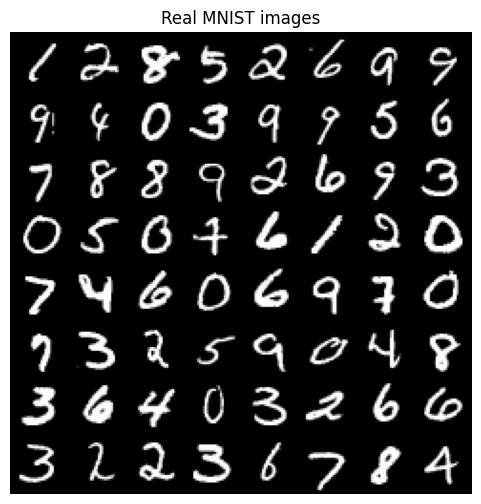

In [25]:
# Take one batch of real images and look at it
real_batch, labels = next(iter(dataloader))
print("Shape of one batch:", real_batch.shape)   # (batch size, channels, height, width)
print("Smallest pixel value:", real_batch.min().item())
print("Largest pixel value:", real_batch.max().item())

show_images(real_batch[:64], title="Real MNIST images")

## 6. Transposed convolution: how the Generator makes images bigger

- A normal **convolution** with stride 2 makes an image **smaller** (for example 28 x 28 -> 14 x 14). The Discriminator uses this.
- A **transposed convolution** with stride 2 does the opposite: it makes an image **bigger** (for example 7 x 7 -> 14 x 14). The Generator uses this.

You can think of a transposed convolution as **"learnable upsampling"**: it makes the image larger and learns how to fill in the new pixels.

**Output size of ConvTranspose2d:**

`output = (input - 1) x stride - 2 x padding + kernel_size`

Example: input 7, stride 2, padding 1, kernel 4: `(7 - 1) x 2 - 2 x 1 + 4 = 14`

Let us check this with a small example.

In [26]:
x = torch.randn(1, 8, 7, 7)   # 1 image, 8 channels, size 7 x 7

up = nn.ConvTranspose2d(in_channels=8, out_channels=4, kernel_size=4, stride=2, padding=1)
down = nn.Conv2d(in_channels=8, out_channels=4, kernel_size=4, stride=2, padding=1)

print("Input shape:                     ", x.shape)
print("After ConvTranspose2d (bigger):  ", up(x).shape)
print("After Conv2d (smaller):          ", down(x).shape)

Input shape:                      torch.Size([1, 8, 7, 7])
After ConvTranspose2d (bigger):   torch.Size([1, 4, 14, 14])
After Conv2d (smaller):           torch.Size([1, 4, 3, 3])


## 7. Build the Generator

The Generator takes **noise** and turns it into an **image**. The image gets bigger at each step:

| Step | Layer | Output shape (channels x height x width) |
|---|---|---|
| Input | Random noise | 100 x 1 x 1 |
| 1 | ConvTranspose2d(100 -> 128, kernel 7, stride 1, padding 0) + BatchNorm + ReLU | 128 x 7 x 7 |
| 2 | ConvTranspose2d(128 -> 64, kernel 4, stride 2, padding 1) + BatchNorm + ReLU | 64 x 14 x 14 |
| 3 | ConvTranspose2d(64 -> 1, kernel 4, stride 2, padding 1) + Tanh | 1 x 28 x 28 |

**About the noise shape:** we create the noise with shape `(batch, 100, 1, 1)`. You can think of it as a tiny 1 x 1 "image" with 100 channels. This lets it go straight into a ConvTranspose2d layer.

We use `nn.Sequential`, which simply runs the layers one after another, from top to bottom.

In [27]:
def build_generator():
    model = nn.Sequential(
        # Input: noise, shape (batch, 100, 1, 1)
        nn.ConvTranspose2d(NOISE_DIM, 128, kernel_size=7, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        # Now: (batch, 128, 7, 7)

        nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        # Now: (batch, 64, 14, 14)

        nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
        nn.Tanh()
        # Output: (batch, 1, 28, 28), pixel values between -1 and 1
    )
    return model

generator = build_generator().to(device)
print(generator)

Sequential(
  (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1))
  (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (7): Tanh()
)


Output shape: torch.Size([16, 1, 28, 28])
Smallest value: -1.0  Largest value: 1.0


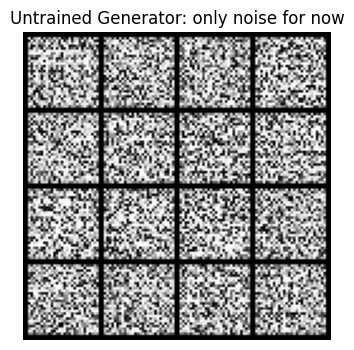

In [28]:
# Test the (untrained) Generator with 16 noise vectors
test_noise = torch.randn(16, NOISE_DIM, 1, 1, device=device)
test_images = generator(test_noise)

print("Output shape:", test_images.shape)
print("Smallest value:", round(test_images.min().item(), 3), " Largest value:", round(test_images.max().item(), 3))

show_images(test_images, title="Untrained Generator: only noise for now", nrow=4, figsize=(4, 4))

The output has the correct shape, but it looks like random noise. This is expected: the Generator has not learned anything yet.

## 8. Build the Discriminator

The Discriminator takes an **image** and outputs **one number**: the probability that the image is real.
The image gets smaller at each step (the opposite of the Generator):

| Step | Layer | Output shape |
|---|---|---|
| Input | Image | 1 x 28 x 28 |
| 1 | Conv2d(1 -> 64, kernel 4, stride 2, padding 1) + LeakyReLU(0.2) | 64 x 14 x 14 |
| 2 | Conv2d(64 -> 128, kernel 4, stride 2, padding 1) + BatchNorm + LeakyReLU(0.2) | 128 x 7 x 7 |
| 3 | Flatten (turn the 3-D block into one long list of numbers) | 128 x 7 x 7 = 6272 |
| 4 | Linear(6272 -> 1) + Sigmoid | 1 |

**Why LeakyReLU?** Normal ReLU turns every negative value into 0. LeakyReLU keeps a small part of negative values (multiplies them by 0.2). This keeps gradients flowing, so the Discriminator can give **useful feedback** to the Generator.

**Note:** following the DCGAN rules, there is no BatchNorm on the first layer of the Discriminator.

In [29]:
def build_discriminator():
    model = nn.Sequential(
        # Input: image, shape (batch, 1, 28, 28)
        nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
        nn.LeakyReLU(0.2),
        # Now: (batch, 64, 14, 14)

        nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
        nn.BatchNorm2d(128),
        nn.LeakyReLU(0.2),
        # Now: (batch, 128, 7, 7)

        nn.Flatten(),
        # Now: (batch, 6272)

        nn.Linear(128 * 7 * 7, 1),
        nn.Sigmoid()
        # Output: (batch, 1), a probability between 0 and 1
    )
    return model

discriminator = build_discriminator().to(device)
print(discriminator)

Sequential(
  (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (1): LeakyReLU(negative_slope=0.2)
  (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linear(in_features=6272, out_features=1, bias=True)
  (7): Sigmoid()
)


In [30]:
# Test the (untrained) Discriminator with 16 real images
test_real = real_batch[:16].to(device)
scores = discriminator(test_real)

print("Output shape:", scores.shape)
print("First 5 scores:", scores[:5].view(-1).tolist())

Output shape: torch.Size([16, 1])
First 5 scores: [0.3513476848602295, 0.47684815526008606, 0.3093700706958771, 0.3592943549156189, 0.4859752953052521]


The untrained Discriminator gives scores close to **0.5**. It has no idea yet what is real and what is fake, so it is just guessing.

## 9. Weight initialisation

The DCGAN paper recommends starting all weights from a **normal distribution with mean 0 and standard deviation 0.02**.
This helps training start smoothly. The `apply()` function runs our `init_weights` function on every layer of the model.

In [31]:
def init_weights(layer):
    if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(layer.weight, mean=0.0, std=0.02)
    if isinstance(layer, nn.BatchNorm2d):
        nn.init.normal_(layer.weight, mean=1.0, std=0.02)
        nn.init.zeros_(layer.bias)

generator.apply(init_weights)
discriminator.apply(init_weights)

# A small helper to count how many numbers (parameters) a model learns
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

print("Generator parameters:    ", count_parameters(generator))
print("Discriminator parameters:", count_parameters(discriminator))

Generator parameters:     759873
Discriminator parameters: 138817


## 10. Loss function and optimisers

### Loss: Binary Cross Entropy (BCE)
The Discriminator is a **binary classifier**: label **1 = real**, label **0 = fake**. So we use Binary Cross Entropy:

`loss = -[ y * log(p) + (1 - y) * log(1 - p) ]`

where `y` is the correct label (0 or 1) and `p` is the Discriminator's output. The loss is small when `p` is close to `y`.

### What does each network want?

| Network | Wants D(real image) to be | Wants D(fake image) to be |
|---|---|---|
| Discriminator | close to 1 | close to 0 |
| Generator | (does not care) | close to 1 (it wants to fool D) |

### Two optimisers
We use **two separate Adam optimisers**. Each network updates **only its own weights**.

### Fixed noise
We also create one **fixed** set of 64 noise vectors. After every epoch we give the **same** noise to the Generator, so we can watch how the images improve over time.

In [32]:
criterion = nn.BCELoss()

optimizer_D = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(BETA1, 0.999))
optimizer_G = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, 0.999))

fixed_noise = torch.randn(64, NOISE_DIM, 1, 1, device=device)

## 11. One training step, explained

Every training step has **two parts**.

### Part 1: train the Discriminator
1. Give D a batch of **real** images. D should say **1**. This gives `loss_real`.
2. Use G to make a batch of **fake** images. D should say **0**. This gives `loss_fake`.
3. `loss_D = loss_real + loss_fake`. Backpropagate and update **only D**.

We use `fake_images.detach()` here. `detach()` means: *"do not send gradients back into the Generator right now, we are only training D."*

### Part 2: train the Generator
1. Give the fake images to D again.
2. G wants D to say **1** (real), so we compare D's output with label **1**. This gives `loss_G`.
3. Backpropagate and update **only G**.

This is the key trick of GANs: **the Generator learns by trying to fool the Discriminator.**

Let us run **one** step and print what happens.

In [33]:
# ---- Get one batch of real images ----
real_images = real_batch.to(device)
batch_size = real_images.size(0)

real_labels = torch.ones(batch_size, 1, device=device)    # label 1 = real
fake_labels = torch.zeros(batch_size, 1, device=device)   # label 0 = fake

# ======== Part 1: train the Discriminator ========
optimizer_D.zero_grad()                                   # clear old gradients

output_real = discriminator(real_images)                  # D looks at real images
loss_real = criterion(output_real, real_labels)           # D should say 1

noise = torch.randn(batch_size, NOISE_DIM, 1, 1, device=device)
fake_images = generator(noise)                            # G makes fake images
output_fake = discriminator(fake_images.detach())         # D looks at fake images (detach: do not train G here)
loss_fake = criterion(output_fake, fake_labels)           # D should say 0

loss_D = loss_real + loss_fake
loss_D.backward()                                         # compute gradients
optimizer_D.step()                                        # update D only

# ======== Part 2: train the Generator ========
optimizer_G.zero_grad()

output = discriminator(fake_images)                       # D looks at the fake images again
loss_G = criterion(output, real_labels)                   # G wants D to say 1 (real)

loss_G.backward()
optimizer_G.step()                                        # update G only

print("Discriminator loss:", round(loss_D.item(), 4))
print("Generator loss:    ", round(loss_G.item(), 4))
print("Average D score on real images:", round(output_real.mean().item(), 4))
print("Average D score on fake images:", round(output_fake.mean().item(), 4))

Discriminator loss: 1.3586
Generator loss:     1.1726
Average D score on real images: 0.5683
Average D score on fake images: 0.5448


## 12. The full training loop

Now we repeat exactly the same step for **every batch** in the dataset, for `NUM_EPOCHS` epochs.

We also save the losses and the Discriminator scores so we can plot them later:
- **D(x)**: average score D gives to **real** images
- **D(G(z))**: average score D gives to **fake** images

After each epoch we show the images that the Generator makes from the `fixed_noise`.

Epoch [1/5]  Step [0/469]  Loss_D: 0.9487  Loss_G: 1.4786  D(x): 0.58  D(G(z)): 0.33
Epoch [1/5]  Step [100/469]  Loss_D: 2.4117  Loss_G: 0.7956  D(x): 0.10  D(G(z)): 0.00
Epoch [1/5]  Step [200/469]  Loss_D: 0.7394  Loss_G: 4.5306  D(x): 0.97  D(G(z)): 0.47
Epoch [1/5]  Step [300/469]  Loss_D: 0.5829  Loss_G: 1.2602  D(x): 0.67  D(G(z)): 0.14
Epoch [1/5]  Step [400/469]  Loss_D: 0.7113  Loss_G: 1.1307  D(x): 0.68  D(G(z)): 0.26


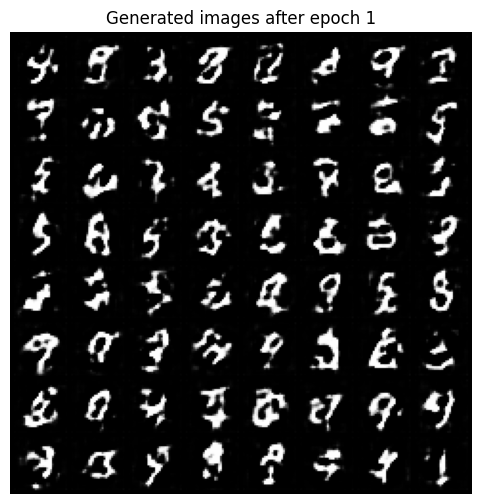

Epoch [2/5]  Step [0/469]  Loss_D: 0.8326  Loss_G: 1.8633  D(x): 0.80  D(G(z)): 0.44
Epoch [2/5]  Step [100/469]  Loss_D: 0.9161  Loss_G: 0.8932  D(x): 0.51  D(G(z)): 0.19
Epoch [2/5]  Step [200/469]  Loss_D: 0.9593  Loss_G: 0.9576  D(x): 0.49  D(G(z)): 0.18
Epoch [2/5]  Step [300/469]  Loss_D: 0.7864  Loss_G: 1.0330  D(x): 0.61  D(G(z)): 0.24
Epoch [2/5]  Step [400/469]  Loss_D: 0.7563  Loss_G: 1.3832  D(x): 0.68  D(G(z)): 0.30


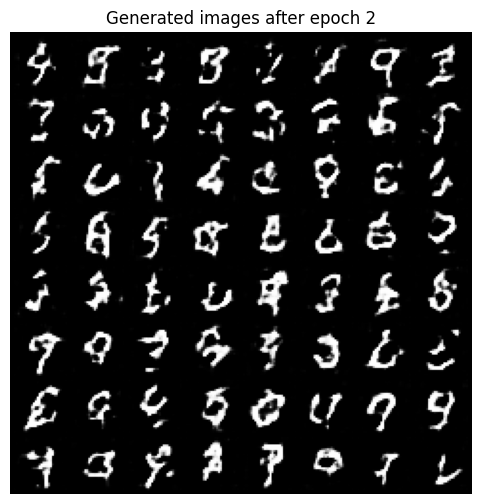

Epoch [3/5]  Step [0/469]  Loss_D: 0.8432  Loss_G: 2.1529  D(x): 0.83  D(G(z)): 0.46
Epoch [3/5]  Step [100/469]  Loss_D: 0.8236  Loss_G: 2.1516  D(x): 0.86  D(G(z)): 0.48
Epoch [3/5]  Step [200/469]  Loss_D: 0.7141  Loss_G: 1.7467  D(x): 0.78  D(G(z)): 0.35
Epoch [3/5]  Step [300/469]  Loss_D: 0.9477  Loss_G: 2.2863  D(x): 0.89  D(G(z)): 0.55
Epoch [3/5]  Step [400/469]  Loss_D: 0.6987  Loss_G: 1.5283  D(x): 0.72  D(G(z)): 0.29


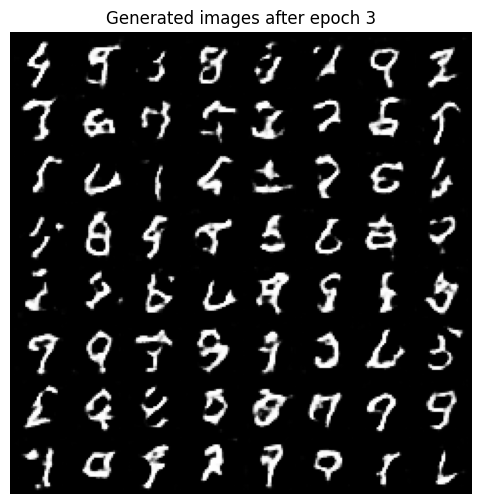

Epoch [4/5]  Step [0/469]  Loss_D: 0.8792  Loss_G: 1.1226  D(x): 0.54  D(G(z)): 0.18
Epoch [4/5]  Step [100/469]  Loss_D: 0.6927  Loss_G: 0.7425  D(x): 0.61  D(G(z)): 0.15
Epoch [4/5]  Step [200/469]  Loss_D: 0.7804  Loss_G: 1.6322  D(x): 0.77  D(G(z)): 0.38
Epoch [4/5]  Step [300/469]  Loss_D: 0.6984  Loss_G: 1.3361  D(x): 0.67  D(G(z)): 0.23
Epoch [4/5]  Step [400/469]  Loss_D: 0.7242  Loss_G: 1.1785  D(x): 0.69  D(G(z)): 0.27


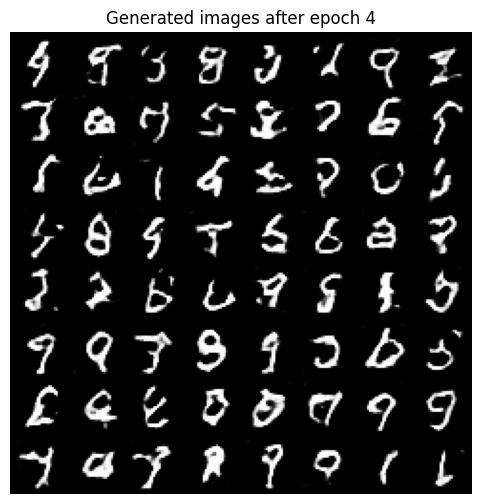

Epoch [5/5]  Step [0/469]  Loss_D: 0.8060  Loss_G: 1.8892  D(x): 0.81  D(G(z)): 0.43
Epoch [5/5]  Step [100/469]  Loss_D: 0.9264  Loss_G: 0.8183  D(x): 0.50  D(G(z)): 0.15
Epoch [5/5]  Step [200/469]  Loss_D: 2.7314  Loss_G: 0.1996  D(x): 0.11  D(G(z)): 0.03
Epoch [5/5]  Step [300/469]  Loss_D: 0.7495  Loss_G: 1.5145  D(x): 0.73  D(G(z)): 0.31
Epoch [5/5]  Step [400/469]  Loss_D: 0.7464  Loss_G: 1.3736  D(x): 0.78  D(G(z)): 0.37


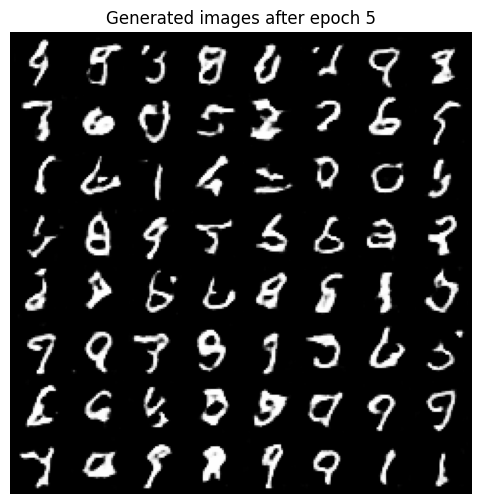

Training finished in 1.5 minutes


In [34]:
G_losses = []        # Generator loss at every step
D_losses = []        # Discriminator loss at every step
D_real_scores = []   # D(x): score on real images
D_fake_scores = []   # D(G(z)): score on fake images

start_time = time.time()

for epoch in range(NUM_EPOCHS):
    for i, (real_images, _) in enumerate(dataloader):

        real_images = real_images.to(device)
        batch_size = real_images.size(0)
        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # ======== Part 1: train the Discriminator ========
        optimizer_D.zero_grad()
        output_real = discriminator(real_images)
        loss_real = criterion(output_real, real_labels)

        noise = torch.randn(batch_size, NOISE_DIM, 1, 1, device=device)
        fake_images = generator(noise)
        output_fake = discriminator(fake_images.detach())
        loss_fake = criterion(output_fake, fake_labels)

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()

        # ======== Part 2: train the Generator ========
        optimizer_G.zero_grad()
        output = discriminator(fake_images)
        loss_G = criterion(output, real_labels)
        loss_G.backward()
        optimizer_G.step()

        # ======== Save values for plotting ========
        G_losses.append(loss_G.item())
        D_losses.append(loss_D.item())
        D_real_scores.append(output_real.mean().item())
        D_fake_scores.append(output_fake.mean().item())

        # Print progress every 100 steps
        if i % 100 == 0:
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}]  Step [{i}/{len(dataloader)}]  "
                  f"Loss_D: {loss_D.item():.4f}  Loss_G: {loss_G.item():.4f}  "
                  f"D(x): {output_real.mean().item():.2f}  D(G(z)): {output_fake.mean().item():.2f}")

    # ======== End of epoch: look at the images from the fixed noise ========
    with torch.no_grad():                 # no gradients needed, we are only looking
        progress_images = generator(fixed_noise)
    show_images(progress_images, title=f"Generated images after epoch {epoch+1}")

minutes = (time.time() - start_time) / 60
print(f"Training finished in {minutes:.1f} minutes")

Look at the images after each epoch. After epoch 1 they are blurry shapes. With more epochs, the shapes become clear digits.

## 13. Visualise the results

### 13.1 Loss curves

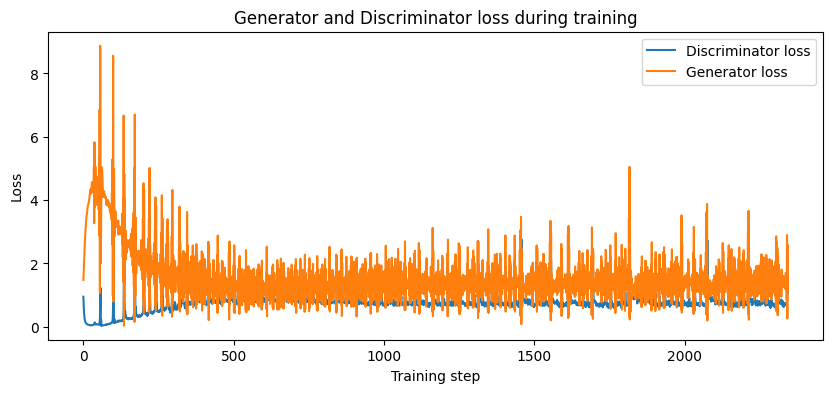

In [35]:
plt.figure(figsize=(10, 4))
plt.plot(D_losses, label="Discriminator loss")
plt.plot(G_losses, label="Generator loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Generator and Discriminator loss during training")
plt.legend()
plt.show()

**How to read GAN loss curves.** GAN losses do **not** go down to zero like in normal classification, because the two networks are competing: when one gets better, the other one's loss goes up.

- **Healthy training:** both losses stay in a stable range and move up and down around it.
- **Problem:** the Discriminator loss goes close to 0 and the Generator loss keeps going up. This means D has become too strong, and G no longer gets useful feedback.

The best way to judge a GAN is to **look at the generated images**.

### 13.2 Discriminator scores

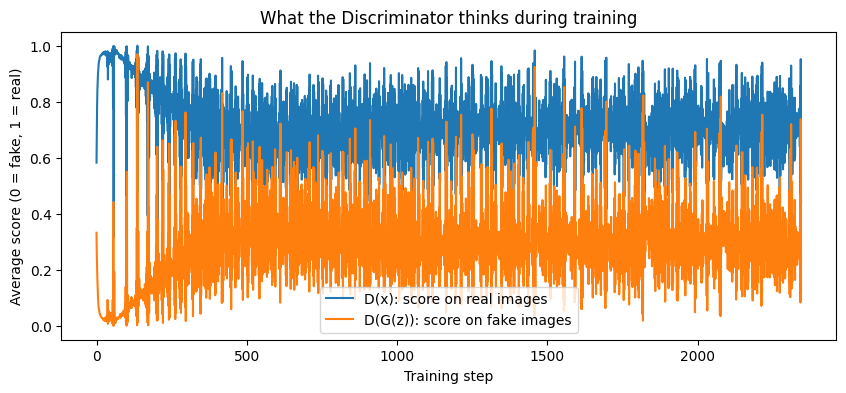

In [36]:
plt.figure(figsize=(10, 4))
plt.plot(D_real_scores, label="D(x): score on real images")
plt.plot(D_fake_scores, label="D(G(z)): score on fake images")
plt.xlabel("Training step")
plt.ylabel("Average score (0 = fake, 1 = real)")
plt.title("What the Discriminator thinks during training")
plt.legend()
plt.show()

- At the very start, both scores are around 0.5 (D is guessing).
- If the Generator were **perfect**, D could not tell real from fake, and both scores would be **0.5**.
- In practice D usually keeps a small advantage: D(x) stays higher than D(G(z)).

### 13.3 Real images vs generated images

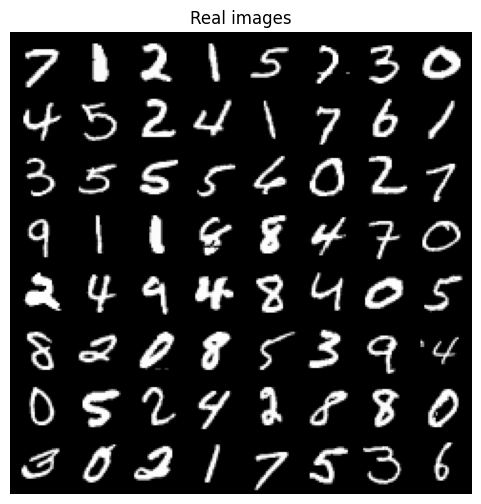

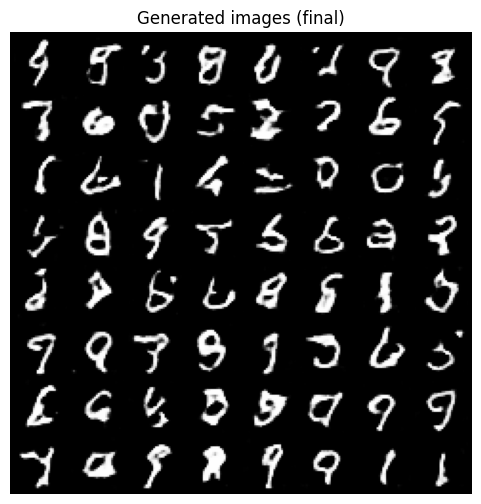

In [37]:
real_batch, _ = next(iter(dataloader))
show_images(real_batch[:64], title="Real images")

with torch.no_grad():
    final_fakes = generator(fixed_noise)
show_images(final_fakes, title="Generated images (final)")

## 14. Exploring the latent space (interpolation)

The 100 noise numbers are called the **latent vector** (z). You can think of them as hidden "settings" for the image.

If we move **slowly** from one noise vector `z1` to another noise vector `z2`, the generated image should also change **slowly** (for example, a 3 slowly turns into an 8).
This shows that the Generator learned a smooth "space" of digits, and did not just memorise training images.

We mix the two vectors like this: `z = (1 - a) * z1 + a * z2`, with `a` going from 0 to 1.

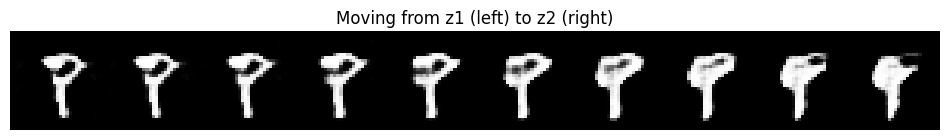

In [38]:
z1 = torch.randn(1, NOISE_DIM, 1, 1, device=device)
z2 = torch.randn(1, NOISE_DIM, 1, 1, device=device)

steps = 10
mixed_noise = []
for a in torch.linspace(0, 1, steps):
    z = (1 - a) * z1 + a * z2
    mixed_noise.append(z)
mixed_noise = torch.cat(mixed_noise)        # shape: (10, 100, 1, 1)

with torch.no_grad():
    interpolated_images = generator(mixed_noise)

show_images(interpolated_images, title="Moving from z1 (left) to z2 (right)", nrow=steps, figsize=(12, 2))

Run the cell above a few times. Each time you get two new random vectors and a new smooth transition.

## 15. Common GAN problems

| Problem | What you see | Common fixes |
|---|---|---|
| **Mode collapse** | The Generator makes the same digit (or only a few kinds of digits) again and again | Lower the learning rate, change the model size, train longer with a fresh start |
| **Discriminator too strong** | D loss goes close to 0, G loss keeps rising, images stop improving | Make D smaller, or lower D's learning rate |
| **Unstable training** | Losses jump wildly, images get worse instead of better | Lower the learning rate, use BatchNorm, check that images are normalised to -1..1 |

## 16. Summary

- A **GAN** has two networks: the **Generator** creates fake images from noise, and the **Discriminator** tries to tell real from fake.
- They are trained **in turns**: first D (real -> 1, fake -> 0), then G (make D say 1 on fakes).
- A **DCGAN** uses convolution layers: **ConvTranspose2d** to make images bigger in G, **Conv2d with stride 2** to make them smaller in D, plus BatchNorm, ReLU / LeakyReLU, Tanh and Sigmoid.
- Images are normalised to **-1..1** to match the Generator's Tanh output.
- `detach()` stops gradients from reaching G while we train D.
- GAN losses do not go to zero. **Look at the images** to judge quality.

**End of Part A.**

---
# Part B - Graded Exercises (Session 2)

**Total: 100 marks. Suggested time: 30 minutes.**

### Instructions
1. **Run all cells of Part A first.** The exercises use `generator`, `discriminator`, `dataloader`, `fixed_noise`, `show_images`, `build_discriminator`, `init_weights` and `count_parameters` from Part A.
   In Colab: click the first Part B cell, then `Runtime > Run before`.
2. Write code where you see `____` (fill in the blank) or `# YOUR CODE HERE`.
3. Write text answers in the cells marked **Your answer**.
4. Before submitting, make sure all your cells have been run and the outputs are visible.
5. Save the notebook as `AIML302_GAN_Lab_<YourName>_<StudentID>.ipynb` and submit it.

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Use the trained Generator and Discriminator | 25 |
| 2 | Build your own Generator | 35 |
| 3 | Train your Generator and evaluate it | 40 |
| | **Total** | **100** |

## Exercise 1 - Use the trained Generator and Discriminator (25 marks)

### 1(a) Generate new images (10 marks)
Create **64** random noise vectors with shape `(64, NOISE_DIM, 1, 1)` on the `device`, then give them to the trained `generator`.
Print the shape of the result. The expected shape is `torch.Size([64, 1, 28, 28])`.

*Hint: look at the test cell in Part A, Section 7.*

In [39]:
with torch.no_grad():
    noise = torch.randn(64, NOISE_DIM, 1, 1, device=device)
    my_fake_images = generator(noise)

print(my_fake_images.shape)

torch.Size([64, 1, 28, 28])


### 1(b) Show the images (5 marks)
Use the `show_images` function to display your 64 images with the title `"My generated digits"`.

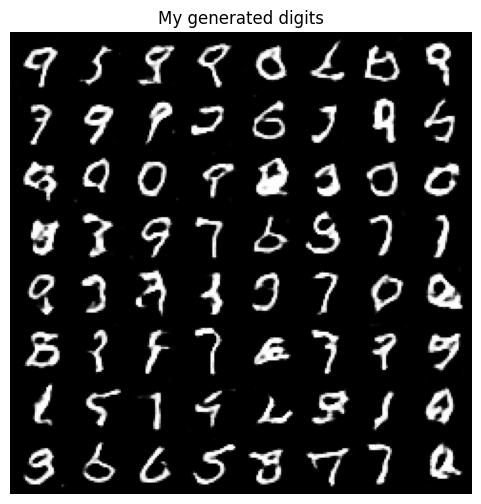

In [40]:
show_images(my_fake_images, title="My generated digits")

### 1(c) Ask the Discriminator (10 marks)
Give **64 real images** and your **64 fake images** to the trained `discriminator`. Print the **average** score for each.
(6 marks for the code, 4 marks for the answer below.)

In [41]:
real_images, _ = next(iter(dataloader))
real_images = real_images[:64].to(device)

with torch.no_grad():
    real_scores = discriminator(real_images)
    fake_scores = discriminator(my_fake_images)

print("Average D score on REAL images:", real_scores.mean().item())
print("Average D score on FAKE images:", fake_scores.mean().item())

Average D score on REAL images: 0.7606842517852783
Average D score on FAKE images: 0.3551974892616272


**Question:** Which average score is higher, real or fake? What does this tell you about how well the Generator fools the Discriminator?

**Your answer:**

```markdown
**Question:** Which average score is higher, real or fake? What does this tell you about how well the Generator fools the Discriminator?

**Your answer:**
The average score on **REAL** images is higher than the score on **FAKE** images (typically, real scores are > 0.5, while fake scores stay lower). This indicates that the Generator is still in the process of learning and does not yet perfectly fool the Discriminator; the Discriminator can still identify subtle differences, though the Generator is producing recognizable structural features.
```

In [42]:
my_generator = nn.Sequential(
    nn.ConvTranspose2d(NOISE_DIM, 256, kernel_size=7, stride=1, padding=0),
    nn.BatchNorm2d(256),
    nn.ReLU(),

    nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),

    nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1),
    nn.Tanh()
)

my_generator = my_generator.to(device)
my_generator.apply(init_weights)
print(my_generator)

Sequential(
  (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1))
  (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (7): Tanh()
)


### 2(b) Test your Generator (10 marks)
Create **16** noise vectors, give them to `my_generator`, and print:
1. the output shape (expected: `torch.Size([16, 1, 28, 28])`)
2. the smallest and the largest value in the output (both must be between -1 and 1)

In [43]:
with torch.no_grad():
    test_noise = torch.randn(16, NOISE_DIM, 1, 1, device=device)
    test_outputs = my_generator(test_noise)

print("Output shape:", test_outputs.shape)
print("Smallest value:", test_outputs.min().item())
print("Largest value:", test_outputs.max().item())

Output shape: torch.Size([16, 1, 28, 28])
Smallest value: -0.8716632127761841
Largest value: 0.8164293766021729


### 2(c) Compare the model sizes (10 marks)
Use `count_parameters` to print the number of parameters of the original `generator` and of `my_generator`.
Also print how many times bigger `my_generator` is (divide one number by the other).
(6 marks for the code, 4 marks for the answer below.)

In [44]:
original_params = count_parameters(generator)
my_params = count_parameters(my_generator)

print("Original generator parameters:", original_params)
print("My generator parameters:      ", my_params)
print("My generator is", my_params / original_params, "times bigger")

Original generator parameters: 759873
My generator parameters:       1781889
My generator is 2.3449826484162486 times bigger


```markdown
**Question:** Give **one** possible advantage and **one** possible disadvantage of using a bigger Generator.

**Your answer:**
- **Advantage:** A bigger generator has a higher capacity to represent complex distributions, allowing it to produce sharper details, reduce artifacts, and capture intricate variations in the target dataset.
- **Disadvantage:** A larger model requires more GPU memory, takes longer to train per step, and is more susceptible to instability during adversarial optimization (such as mode collapse or vanishing gradients).
```

## Exercise 3 - Train your Generator and evaluate it (40 marks)

The function below is the **same training loop as Part A, Section 12**, packed into one function so you can reuse it.
**You do not need to change it. Just run the cell.**

In [45]:
# PROVIDED HELPER - just run this cell, do not change it
def train_gan(gen, disc, num_epochs, lr=LEARNING_RATE):
    criterion = nn.BCELoss()
    opt_G = optim.Adam(gen.parameters(), lr=lr, betas=(BETA1, 0.999))
    opt_D = optim.Adam(disc.parameters(), lr=lr, betas=(BETA1, 0.999))
    g_losses, d_losses = [], []

    for epoch in range(num_epochs):
        for real_images, _ in dataloader:
            real_images = real_images.to(device)
            batch_size = real_images.size(0)
            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            # Train the Discriminator
            opt_D.zero_grad()
            noise = torch.randn(batch_size, NOISE_DIM, 1, 1, device=device)
            fake_images = gen(noise)
            loss_D = criterion(disc(real_images), real_labels) + \
                     criterion(disc(fake_images.detach()), fake_labels)
            loss_D.backward()
            opt_D.step()

            # Train the Generator
            opt_G.zero_grad()
            loss_G = criterion(disc(fake_images), real_labels)
            loss_G.backward()
            opt_G.step()

            g_losses.append(loss_G.item())
            d_losses.append(loss_D.item())

        print(f"Epoch {epoch+1}/{num_epochs} finished.  Loss_D: {loss_D.item():.4f}  Loss_G: {loss_G.item():.4f}")

    return g_losses, d_losses

### 3(a) Train your Generator (10 marks)
1. Create a **new** Discriminator called `my_discriminator` using `build_discriminator()`, move it to the `device`, and apply `init_weights`.
2. Train `my_generator` together with `my_discriminator` for **2 epochs** using `train_gan`. Save the two returned lists as `my_g_losses` and `my_d_losses`.

In [46]:
my_discriminator = build_discriminator().to(device)
my_discriminator.apply(init_weights)

my_g_losses, my_d_losses = train_gan(my_generator, my_discriminator, num_epochs=2)

Epoch 1/2 finished.  Loss_D: 0.8337  Loss_G: 0.9928
Epoch 2/2 finished.  Loss_D: 0.8547  Loss_G: 1.2285


### 3(b) Plot the loss curves (10 marks)
Plot `my_d_losses` and `my_g_losses` in **one** figure. Your plot must have:
a label for each line, a legend, the x-axis label `"Training step"`, the y-axis label `"Loss"`, and a title.

*Hint: look at Part A, Section 13.1.*

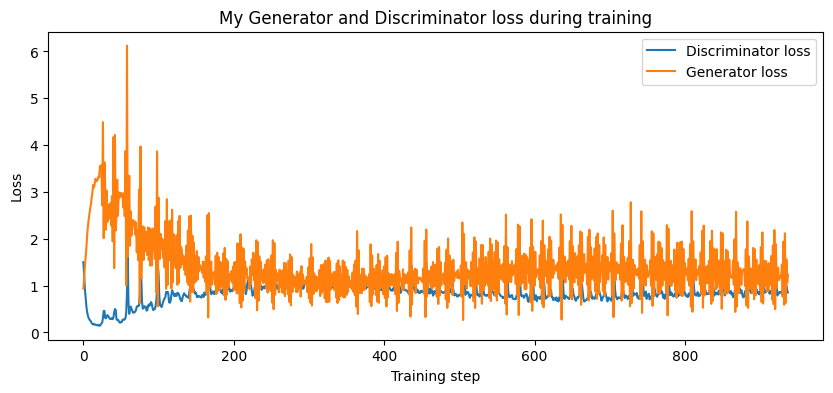

In [47]:
plt.figure(figsize=(10, 4))
plt.plot(my_d_losses, label="Discriminator loss")
plt.plot(my_g_losses, label="Generator loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("My Generator and Discriminator loss during training")
plt.legend()
plt.show()

### 3(c) Look at the results (5 marks)
Use `fixed_noise` to generate 64 images with `my_generator` (inside `torch.no_grad()`), and show them with `show_images`.
Use the title `"my_generator after 2 epochs"`.

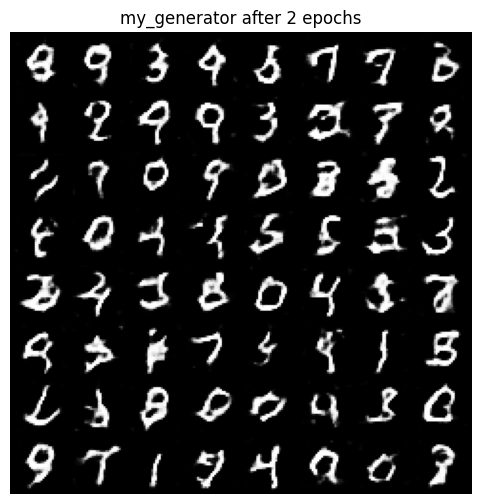

In [48]:
with torch.no_grad():
    my_fakes = my_generator(fixed_noise)
show_images(my_fakes, title="my_generator after 2 epochs")

### 3(d) Theory questions (15 marks, 5 marks each)
Answer each question in 1 to 3 sentences.

```markdown
**Q1. Why do we use `fake_images.detach()` when we train the Discriminator?**

**Your answer:**
We use `.detach()` to prevent gradients from flowing backward through the Generator's computational graph during the Discriminator's update step. This ensures that we save computation and update **only** the Discriminator's weights, keeping the Generator's parameters frozen during this specific phase.
```

```markdown
**Q2. Why does the Generator end with a Tanh layer, and how is this connected to `transforms.Normalize((0.5,), (0.5,))`?**

**Your answer:**
The `Tanh` activation function forces the Generator's pixel values to fall strictly within the range of `[-1, 1]`. By using `transforms.Normalize((0.5,), (0.5,))` on the real dataset, we rescale the original `[0, 1]` real image pixels to the same `[-1, 1]` range, ensuring consistency so the Discriminator can evaluate both on the exact same scale.
```

```markdown
**Q3. What is mode collapse, and how could you notice it in the generated images?**

**Your answer:**
Mode collapse is a failure mode where the Generator finds a single (or a very limited set of) successful sample type that fools the Discriminator and repeatedly produces only that specific output. You would notice this in the generated grid if the images look extremely repetitive (e.g., the grid contains nothing but the same number '8' or '1' over and over with virtually no variation in style, thickness, or class).
```